In [2]:
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams["font.family"] = "FreeSerif"
plt.rcParams.update({'font.size': 18})
plt.rc('legend', fontsize=16)    # legend fontsize
plt.rcParams['mathtext.fontset'] = 'stix'


import dfmux_calc as d
from scipy.stats import norm
import nep_calc as nep
import pickle as pk



In [3]:
# load measured overbiased noise
noise_dir = '/home/nfarias/nicole_data/unzipped_measure_noise/'
noise_file = noise_dir + '20230912_003547_measure_noise/data/2785_BOLOS_INFO_AND_MAPPING.pkl'

di = pk.load(open(noise_file,'rb'))
nei = []
fbias = []
for k in di.keys():
    if di[k]['calc_R']['V'] !=0:
        fbias.append(di[k]['frequency']/1e6)
        nei.append(di[k]['noise']['i_phase']['median_noise'])

# load measured squid properties
pb_sqs = pk.load(open('/home/nfarias/nicole_data/unzipped_measure_noise/20230911_222403_SQUIDParams.pkl', 'rb'))
zt =  [pb_sqs[k]['transimpedance'] for k in pb_sqs.keys()]
rdyn =  [pb_sqs[k]['output_impedance'] for k in pb_sqs.keys()]

In [4]:
# Detector bias frequencies [Hz]
f = np.linspace(1.5e6, 4.5e6, 40)

#SA13 properties representative of the median SAA
sa13 = d.squid( zt,                                        #Transimpedence [Ohms]
                rdyn,                                      #Dynamic impedance [Ohms]
               5e-12*np.sqrt(np.median(zt)/np.array(zt)),  #NEI [A/rtHz] (just taking the number JM used)
               70e-9,                                      #Input inductance [H]
               n_series=3*64,n_parallel=2,power=80e-9,     #array size and power dissipation
               snubber=20,                                 #if there is a snubber on the input
               t=4)                                        #what temperature the SAA is at [K]

#Wiring harness properties
wh = d.wire(30,                            #resistance [Ohms]
            40e-12,                        #capacitance [F] (this is the important one)
            0.75e-6,                       #inductance  [H]
            rshunt=False, cshunt=False)    #if theres any resistive or capcitive shunts across the output of the SAA

rstray = np.array([0.14889617, 0.22575848, 0.17266659, 0.21391573, 0.21293207, 0.20291612,
 0.17974052, 0.13675212, 0.13878973, 0.19187134, 0.0703359 , 0.17498834,
 0.17734522, 0.16321762, 0.07591814, 0.11368773, 0.25449139, 0.15703011,
 0.22348886, 0.16820122, 0.19569417, 0.1801744 , 0.24450427, 0.24594952,
 0.18425028, 0.22912093, 0.23812164, 0.27830734, 0.21009893, 0.23573789,
 0.14902439, 0.27297393, 0.28568549, 0.19467917, 0.18442179, 0.25035455,
 0.22820852, 0.23692354, 0.15921249, 0.20781176])

# seed = np.random.rand(100)

#Other parasitics
para = d.parasitics(45e-12,0.7e-9,0) #stripline inductance[H], parasitic capacitance to ground[F] and R48 [Ohms]

Unsupported Ngspice version 36


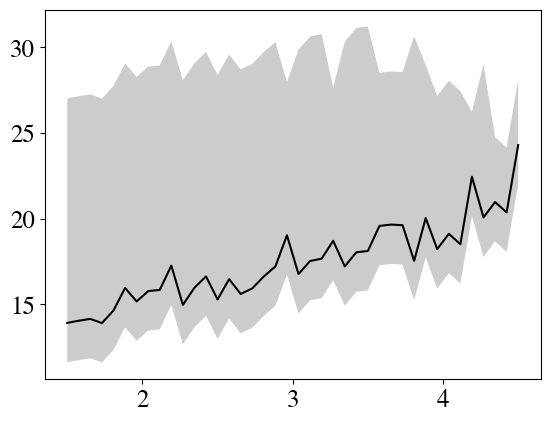

In [5]:
# Calculate overbiased noise

# generate array of rbolo and rstray
rbolo = np.array([0.9626058,  0.92854195, 0.97671754, 1.02534344, 0.90712921, 0.73541908,
 0.88514277, 0.84788629, 0.84710096, 0.673961,   1.08811606, 0.8800057,
 0.81783305, 1.03562617, 0.94716845,  1.07323231, 0.94703383, 0.94293215,
 0.84598007, 0.7227199 , 0.95915082,  0.90167417, 0.8608948 , 0.77598358,
 1.01380923, 0.89051242, 0.89894448,  0.74779782, 0.81738237, 0.82166417,
 1.14899087, 0.78721942, 1.00131014,  0.98617771, 1.10378498, 0.71130264,
 0.93687832, 0.87447909, 1.034875  ,  0.72230782] )

#bolometer properties
bolo = d.bolo(rbolo,            #operating impedence [Ohms]
              0,              #loopgain
              rstray,            #stray impedence [Ohms]
              5e-12,          #psat - this isn't used at all
              2e-12,
              0.5, 0.5)        #Tc and Tb [K]

#PB noise expectations
pb_noise = d.dfmux_noise(sa13, bolo, wh, para, nuller_cold=False,bias_res=True)
pb_noise.init_freq(f, csf_factor=1.0) 
ob_l0 = pb_noise.total.copy()

err_plus = np.zeros(40)
err_minus = np.zeros(40)

for i in range(40):
    err_plus[i] = np.std(ob_l0[(ob_l0[:,i]>np.median(ob_l0[:,i])) & (ob_l0[:,i]<100e-12)])*1e12
    err_minus[i] = np.std(ob_l0[ob_l0[:,i]<np.median(ob_l0[:,i])])*1e12



In [7]:
bolo.loopgain = np.array([1.6])
bolo.r = rbolo * 0.75
pb_noise = d.dfmux_noise(sa13, bolo, wh, para, nuller_cold=False, bias_res=True)
pb_noise.init_freq(f,csf_factor=1.0)
r0p75_l1p6 = pb_noise.total.copy()

err_plus_t = np.zeros(40)
err_minus_t = np.zeros(40)

for i in range(40):
    err_plus_t[i] = np.std(r0p75_l1p6[(r0p75_l1p6[:,i]>np.median(r0p75_l1p6[:,i])) & (r0p75_l1p6[:,i]<100e-12)])*1e12
    err_minus_t[i] = np.std(r0p75_l1p6[r0p75_l1p6[:,i]<np.median(r0p75_l1p6[:,i])])*1e12


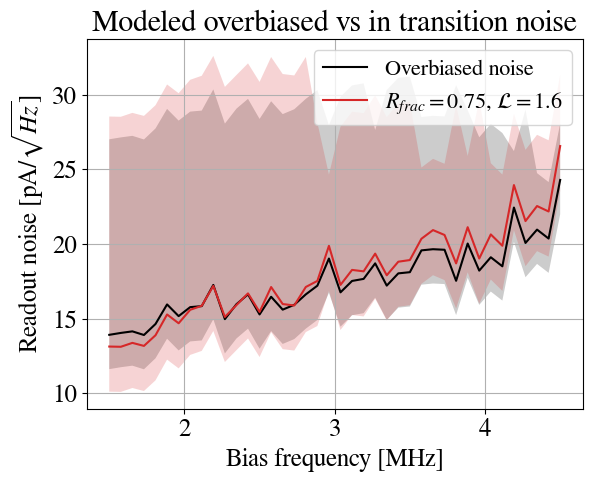

Text(0, 0.5, 'Number of channels')

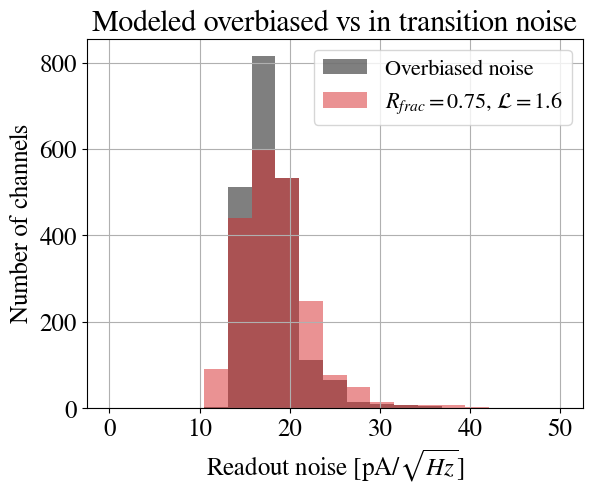

In [9]:
# Make plots

plt.plot(f/1e6, np.median(ob_l0,axis=0)*1e12,c='k',label='Overbiased noise')
plt.fill_between(f/1e6, np.median(ob_l0,axis=0)*1e12 - err_minus, np.median(ob_l0,axis=0)*1e12 +err_plus,facecolor='k',alpha=0.2)

plt.plot(f/1e6, np.median(r0p75_l1p6,axis=0)*1e12,c='tab:red',label='$R_{frac}=0.75$, $\mathcal{L}=1.6$')
plt.fill_between(f/1e6, np.median(r0p75_l1p6,axis=0)*1e12 - err_minus_t, np.median(r0p75_l1p6,axis=0)*1e12 +err_plus_t,facecolor='tab:red',alpha=0.2)

plt.xlabel('Bias frequency [MHz]')
plt.ylabel('Readout noise [pA/$\sqrt{Hz}$]')
#plt.title('$NEI_{SQ}=5pA/\sqrt{Hz}$, $C_{wire}=40$pF')
plt.title('Modeled overbiased vs in transition noise')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.hist(ob_l0.flatten()*1e12,bins=np.linspace(0,50,20),alpha = 0.5,color='k',label='Overbiased noise', weights = np.ones(len(pb_noise.total.flatten()))*len(nei)/len(pb_noise.total.flatten()))
plt.hist(r0p75_l1p6.flatten()*1e12,bins=np.linspace(0,50,20),alpha = 0.5,color='tab:red',label='$R_{frac}=0.75$, $\mathcal{L}=1.6$',weights = np.ones(len(pb_noise.total.flatten()))*len(nei)/len(pb_noise.total.flatten()))
plt.legend()
plt.grid(True)
plt.xlabel('Readout noise [pA/$\sqrt{Hz}$]')
plt.title('Modeled overbiased vs in transition noise')
plt.ylabel('Number of channels')